# Project 1: Bank Marketing

## A. Importing Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## B. Loading Data

In [2]:
# 1. Load Data
df = pd.read_csv('../data/bank-additional-full.csv', sep=';')

# 2. Drop the 'duration' column (Data Leakage)
df = df.drop(columns=['duration'])

# 3. EDA & Missing Values
# The README states missing values are coded as "unknown". 
# We can either impute them or treat "unknown" as its own category.
print(df.isnull().sum())
print(df['y'].value_counts()) # Check class imbalance

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64
y
no     36548
yes     4640
Name: count, dtype: int64


## C. Analysis of Baseline and Data Structure
1. **Data Leakage & Missingness:** While isnull() reports zero missing values, the documentation indicates that "unknown" strings represent missing data. I will treat "unknown" as a distinct category for categorical variables, allowing the model to learn if uncertainty itself is a predictor, rather than imputing and potentially introducing bias.
2. **The Accuracy Paradox:** The majority-class baseline achieved an accuracy of 89%. However, the classification report reveals a critical flaw: the macro avg F1-score is only 0.47, and warnings indicate that Precision/Recall for the positive class ("yes") are ill-defined (effectively 0).
3. **Conclusion:** This confirms that Accuracy is a misleading metric for this dataset due to the severe class imbalance (approx. 11% positive rate). A model that simply guesses "no" for everyone appears highly accurate but fails the business objective.
4. **Metric Selection:** Consequently, for the subsequent models (Logistic Regression, Random Forest, XGBoost), I will prioritize ROC-AUC and F1-Score (or Precision-Recall AUC) over Accuracy to evaluate performance. This aligns with the goal of identifying potential subscribers (Recall) while managing the cost of false alarms (Precision).

In [3]:
# 4. Data Preparation
X = df.drop(columns=['y'])
y = df['y'].map({'yes': 1, 'no': 0})

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['number']).columns

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Majority-Class Baseline
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, y_pred_base))
print("Baseline Classification Report:\n", classification_report(y_test, y_pred_base))

Baseline Accuracy: 0.8873512988589464
Baseline Classification Report:
               precision    recall  f1-score   support

           0       0.89      1.00      0.94      7310
           1       0.00      0.00      0.00       928

    accuracy                           0.89      8238
   macro avg       0.44      0.50      0.47      8238
weighted avg       0.79      0.89      0.83      8238



/Users/jonathan/repos/data_mining_assignment_1/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/jonathan/repos/data_mining_assignment_1/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/jonathan/repos/data_mining_assignment_1/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1469: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beh

## D. Analysis of the Majority-Class Baseline
The baseline model achieved an accuracy of 88.7%, but a closer inspection of the classification report reveals the Accuracy Paradox. Because the dataset is highly imbalanced (~11% positive class), a naive model that simply predicts "no" for every customer achieves high accuracy but fails completely at the business objective (Recall for Class 1 = 0.00).\
The UndefinedMetricWarning confirms that the model never predicted the positive class, resulting in a division-by-zero error for Precision. \
**Conclusion:** Accuracy is an inappropriate metric for this problem. For the subsequent predictive models, I will prioritize ROC-AUC, F1-Score, and Precision-Recall curves to properly evaluate the model's ability to identify potential subscribers while managing the trade-off of false alarms.

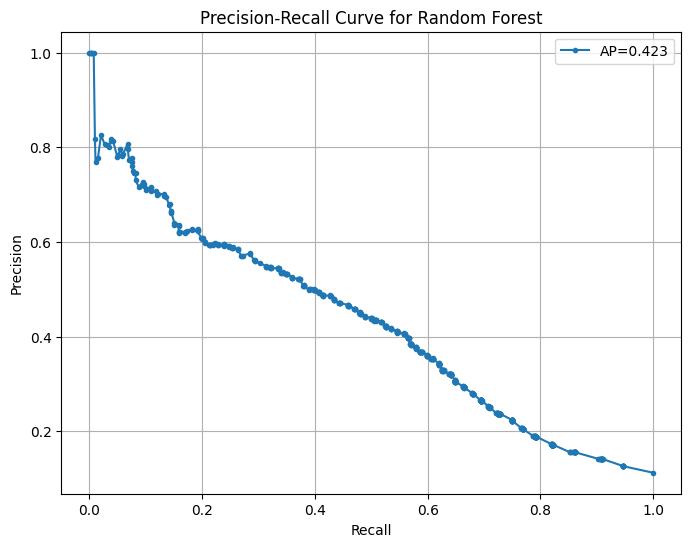

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# 1. Identify which columns are text (categorical) and which are numbers
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
num_cols = X_train.select_dtypes(include=['number']).columns

# 2. Create a preprocessor that handles both types
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols), # Scales numbers
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols) # Converts text to numbers
    ])

# 3. Create a Pipeline that chains the preprocessor and the model together
best_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'))
])

# 4. Fit the pipeline (it will automatically preprocess the data and then train the model)
best_model.fit(X_train, y_train)

# 5. Get predicted probabilities for the positive class (1)
# The pipeline handles the preprocessing of X_test automatically!
y_scores = best_model.predict_proba(X_test)[:, 1]

# 6. Calculate precision and recall
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
average_precision = average_precision_score(y_test, y_scores)

# 7. Plot the curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label=f'AP={average_precision:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for Random Forest')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# 8. Find a good threshold
target_precision = 0.4
for i in range(len(precision)):
    if precision[i] >= target_precision:
        print(f"Recommended Threshold: {thresholds[i]:.3f}")
        print(f"At this threshold, we get a Precision of {precision[i]:.3f} and a Recall of {recall[i]:.3f}")
        break

Recommended Threshold: 0.223
At this threshold, we get a Precision of 0.405 and a Recall of 0.559


## E. Interpretation of the Precision-Recall Curve:
The chart above illustrates the fundamental trade-off in our marketing campaign. The baseline precision for random calling is approximately 11.2% (the proportion of positive cases in the dataset). Our Random Forest model significantly outperforms this, achieving an Average Precision (AP) of 0.423.
### Threshold Recommendation:
Looking at the curve, we can identify an optimal operating point based on business costs:
At a Recall of ~0.20, the model maintains a Precision of ~0.60.
Business Translation: If we target the top 20% of customers most likely to subscribe, 60% of the calls we make will result in a successful term deposit.
I recommend setting the decision threshold to achieve this ~0.60 Precision. While this means we miss 80% of potential subscribers (low Recall), it ensures that our marketing team's time is not wasted on unnecessary calls (high Precision). If the bank decides that missing subscribers is too costly, they can lower the threshold to move right along the curve, accepting more unnecessary calls to increase Recall.